# U2: Ultrasound EfficientNetB0 Frozen-backbone Baseline

**Experiment:** ImageNet-pretrained EfficientNetB0 with a frozen feature extractor and a six-class ultrasound plane classification head. U2 provides a controlled architecture comparison with the completed MobileNetV2 baseline (U1).

**Data:** FETAL_PLANES_DB, 12,400 images from 1,792 patient identifiers. The *existing, audited* patient-separated manifest is used unchanged: 5,818 training images, 1,311 validation images, and 5,271 held-out test images. **No held-out test images are decoded, evaluated, or used to choose a model in this notebook.**

**Comparison protocol:** The U1 settings are retained where applicable: input 224 × 224, aspect-ratio-preserving padded resize, batch size 16, seed 42, frozen backbone, global average pooling, dropout 0.2, Adam at 0.001, balanced class weights, no additional training augmentation, up to six epochs, and early stopping/checkpoint selection using the lowest validation loss (patience 2). The architecture and its required input preprocessing differ: **EfficientNetB0 includes preprocessing and accepts float32 pixels in [0, 255]**; no external MobileNetV2-style scaling is applied.

**Execution:** Run sections sequentially and inspect each result. `train_new` will never overwrite an existing U2 run. After a successful completed run, `evaluate_saved` can repeat validation/report export without retraining. Images and checkpoints remain in Google Drive or temporary Colab storage according to their documented roles. A GPU-enabled Colab runtime is required for training.

**Scope:** These are image classification experiments, not a clinically validated diagnostic system. Softmax outputs are uncalibrated model scores. This experiment contains no fine-tuning, Grad-CAM, or final test evaluation.


## 1. Drive sources and preparation records

Mount Google Drive and read the existing archive, candidate split manifest, class mapping, and preparation audit. Record source fingerprints without changing any source files. Missing or empty files halt execution. The source archive is checked in Section 4.


In [ ]:
# Open saved project sources; do not download or regenerate the dataset.
from google.colab import drive
from pathlib import Path, PurePosixPath
from IPython.display import display
import hashlib
import json
import pandas as pd

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/ICTIU_Final_Projects')
PROJECT = ROOT / 'ultrasound'
SOURCE_FILES = {
    'archive': PROJECT / 'archives/FETAL_PLANES_ZENODO.zip',
    'manifest': PROJECT / 'splits/manifest_candidate.csv',
    'mapping': PROJECT / 'splits/class_mapping.json',
    'audit': PROJECT / 'results/audit.json',
}

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as source:
        for block in iter(lambda: source.read(4 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def read_json(path):
    with Path(path).open('r', encoding='utf-8-sig') as source:
        return json.load(source)

for role, path in SOURCE_FILES.items():
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'Missing or empty {role}: {path}')
    print(f'FOUND: {path.relative_to(ROOT)} ({path.stat().st_size / (1024**2):,.2f} MiB)')

raw_manifest = pd.read_csv(
    SOURCE_FILES['manifest'],
    dtype={'stem': str, 'relative_path': str, 'group_id': str, 'sha256': str},
    keep_default_na=False,
)
raw_mapping = read_json(SOURCE_FILES['mapping'])
saved_audit = read_json(SOURCE_FILES['audit'])
SOURCE_SHA256 = {
    role: sha256_file(SOURCE_FILES[role])
    for role in ('manifest', 'mapping', 'audit')
}
print('Manifest rows:', len(raw_manifest))
print('Manifest columns:', raw_manifest.columns.tolist())
print('Class mapping:', json.dumps(raw_mapping, sort_keys=True))
print('Audit status:', saved_audit.get('status'))
print('Source files are available; no split or source file was modified.')


FOUND: ultrasound/archives/FETAL_PLANES_ZENODO.zip (1,991.77 MiB)
FOUND: ultrasound/splits/manifest_candidate.csv (1.97 MiB)
FOUND: ultrasound/splits/class_mapping.json (0.00 MiB)
FOUND: ultrasound/results/audit.json (0.00 MiB)
Manifest rows: 12400
Manifest columns: ['stem', 'class_name', 'group_id', 'official_train', 'relative_path', 'split', 'width', 'height', 'original_mode', 'sha256', 'class_id']
Class mapping: {"Fetal abdomen": 0, "Fetal brain": 1, "Fetal femur": 2, "Fetal thorax": 3, "Maternal cervix": 4, "Other": 5}
Audit status: PASS_candidate_split_checks
Source files are available; no split or source file was modified.


## 2. Fixed patient-level split and label verification

Verify the *saved* split rather than recomputing it. Check the audit checksum, all six class IDs, official train/test assignments, per-split image and patient counts, patient non-overlap, relative paths, and recorded cross-split SHA-256 hashes. Test metadata are checked only to protect the held-out partition; test images are not opened.


In [ ]:
# Validate the exact U1 class mapping and previously audited patient split.
import numpy as np

EXPECTED_CLASS_MAPPING = {
    'Fetal abdomen': 0,
    'Fetal brain': 1,
    'Fetal femur': 2,
    'Fetal thorax': 3,
    'Maternal cervix': 4,
    'Other': 5,
}
EXPECTED_IMAGES = {'train': 5818, 'validation': 1311, 'test': 5271}
EXPECTED_PATIENTS = {'train': 716, 'validation': 180, 'test': 896}
REQUIRED_COLUMNS = {
    'stem', 'relative_path', 'class_name', 'class_id',
    'group_id', 'official_train', 'split', 'sha256',
}
if not REQUIRED_COLUMNS.issubset(raw_manifest.columns):
    raise ValueError(f'Missing manifest columns: {sorted(REQUIRED_COLUMNS - set(raw_manifest.columns))}')
if raw_mapping != EXPECTED_CLASS_MAPPING:
    raise ValueError('The saved class mapping differs from the six-class U1 mapping.')
if saved_audit.get('status') != 'PASS_candidate_split_checks':
    raise ValueError('The original split audit did not report PASS.')
if saved_audit.get('manifest_sha256') != SOURCE_SHA256['manifest']:
    raise ValueError('Manifest bytes differ from the preparation audit checksum.')

manifest = raw_manifest.copy()
manifest['split'] = manifest['split'].astype(str).str.strip()
manifest['group_id'] = manifest['group_id'].astype(str).str.strip()
manifest['class_name'] = manifest['class_name'].astype(str).str.strip()
manifest['relative_path'] = manifest['relative_path'].astype(str).str.strip()
manifest['sha256'] = manifest['sha256'].astype(str).str.strip().str.lower()
manifest['class_id'] = pd.to_numeric(manifest['class_id'], errors='raise').astype('int32')
manifest['official_train'] = pd.to_numeric(manifest['official_train'], errors='raise').astype('int32')

if (manifest[['stem', 'group_id', 'class_name', 'relative_path', 'sha256']] == '').any().any():
    raise ValueError('Missing identifiers, class names, paths, or recorded image hashes.')
if set(manifest['split']) != set(EXPECTED_IMAGES):
    raise ValueError('Unexpected split names; the saved value must be "validation", not "val".')
if manifest['relative_path'].duplicated().any() or manifest['stem'].duplicated().any():
    raise ValueError('Duplicate saved image paths or stems.')
for relative in manifest['relative_path']:
    path = PurePosixPath(relative)
    if (path.is_absolute() or '..' in path.parts or not path.parts
            or '\\' in relative or path.suffix.lower() not in {'.png', '.jpg', '.jpeg'}):
        raise ValueError(f'Unsafe or unexpected image path: {relative!r}')
if set(manifest['class_name']) != set(EXPECTED_CLASS_MAPPING):
    raise ValueError('Unexpected class names.')
if not manifest['class_id'].eq(manifest['class_name'].map(EXPECTED_CLASS_MAPPING)).all():
    raise ValueError('Saved class labels and class IDs disagree.')
if not ((manifest['official_train'] == 0) == (manifest['split'] == 'test')).all():
    raise ValueError('Official testing patients were not preserved correctly.')
if manifest.groupby('group_id')['split'].nunique().max() != 1:
    raise ValueError('A patient identifier appears in multiple splits.')
if not manifest['sha256'].str.fullmatch(r'[0-9a-f]{64}').all():
    raise ValueError('Missing or malformed image SHA-256 in the saved manifest.')
if manifest.groupby('sha256')['split'].nunique().max() != 1:
    raise ValueError('Recorded byte-identical image hashes cross the saved split boundary.')

image_counts = manifest['split'].value_counts().to_dict()
patient_counts = manifest.groupby('split')['group_id'].nunique().to_dict()
if image_counts != EXPECTED_IMAGES or patient_counts != EXPECTED_PATIENTS:
    raise ValueError(f'Saved split counts changed: images={image_counts}, patients={patient_counts}')
if manifest['group_id'].nunique() != 1792:
    raise ValueError('The expected 1,792 patient IDs were not found.')
if (pd.crosstab(manifest['split'], manifest['class_name']) == 0).any().any():
    raise ValueError('A class is absent from a split.')
class_to_id = dict(EXPECTED_CLASS_MAPPING)
class_names = [name for name, idx in sorted(class_to_id.items(), key=lambda item: item[1])]
id_to_class = {idx: name for name, idx in class_to_id.items()}
DATA_CHECKS = {
    'original_manifest_sha256': SOURCE_SHA256['manifest'],
    'images_per_split': EXPECTED_IMAGES,
    'patients_per_split': EXPECTED_PATIENTS,
    'unique_patients': 1792,
    'patients_spanning_splits': 0,
    'recorded_cross_split_exact_duplicates': 0,
    'split_unit': 'patient identifier',
    'source_test_images_decoded': False,
}
print('Class order:', class_names)
display(pd.crosstab(manifest['split'], manifest['class_name']).reindex(
    ['train', 'validation', 'test']))
print('Patient counts:', patient_counts)
print('Split verification passed; test metadata only, no test image pixels read.')


Class order: ['Fetal abdomen', 'Fetal brain', 'Fetal femur', 'Fetal thorax', 'Maternal cervix', 'Other']


class_name,Fetal abdomen,Fetal brain,Fetal femur,Fetal thorax,Maternal cervix,Other
split,,,,,,
train,282,1289,404,828,765,2250
validation,71,331,112,230,216,351
test,358,1472,524,660,645,1612


Patient counts: {'test': 896, 'train': 716, 'validation': 180}
Split verification passed; test metadata only, no test image pixels read.


## 3. Runtime, training settings, and run protection

Request a GPU, record the environment, and set the fixed U2 protocol. `train_new` is the default and refuses to use a non-empty output directory. After U2 has completed successfully, `evaluate_saved` may be selected for validation-only re-evaluation; it does not retrain the model. Mixed precision and extra augmentation are disabled to keep the U1 comparison interpretable.


In [ ]:
# Reproducible runtime configuration and run safeguards.
import importlib.metadata
import platform
import subprocess
import sys
from datetime import datetime, timezone
import tensorflow as tf
from tensorflow import keras

MODE = 'train_new'   # 'train_new' or 'evaluate_saved'
RUN_NAME = 'U2_EfficientNetB0_frozen_seed42'
RUN_DIR = PROJECT / 'results' / RUN_NAME
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
MAX_EPOCHS = 6
PATIENCE = 2
LEARNING_RATE = 0.001
DROPOUT = 0.2
SMOKE_TEST_PASSED = False

if MODE not in {'train_new', 'evaluate_saved'}:
    raise ValueError('Invalid MODE.')
if RUN_NAME != Path(RUN_NAME).name or not RUN_NAME.startswith('U2_'):
    raise ValueError('RUN_NAME must be a single directory name beginning with U2_.')
if MODE == 'train_new' and RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    raise FileExistsError(f'Run directory is already non-empty: {RUN_DIR}. No overwrite is permitted.')
if MODE == 'evaluate_saved':
    for name in ['configuration.json', 'best_model.keras', 'training_history.csv', 'training_status.json']:
        if not (RUN_DIR / name).is_file():
            raise FileNotFoundError(f'Missing saved-run file: {RUN_DIR / name}')
    SAVED_CONFIG = read_json(RUN_DIR / 'configuration.json')

GPUS = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__)
print('GPU devices:', GPUS)
if not GPUS:
    raise RuntimeError('No Colab GPU detected; select a T4 GPU runtime before proceeding.')
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
keras.mixed_precision.set_global_policy('float32')
keras.utils.set_random_seed(SEED)
# U1 did not request op determinism; keep its seeding and data pipeline protocol.

def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return 'not installed'
try:
    gpu_info = subprocess.check_output(
        ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
        text=True, timeout=10,
    ).strip()
except (OSError, subprocess.SubprocessError):
    gpu_info = str(GPUS)
ENVIRONMENT = {
    'recorded_utc': datetime.now(timezone.utc).isoformat(),
    'python': sys.version,
    'platform': platform.platform(),
    'tensorflow': tf.__version__,
    'gpu': gpu_info,
    'keras_float_policy': keras.mixed_precision.global_policy().name,
    'seed': SEED,
    'tensorflow_op_determinism_requested': False,
    'packages': {name: package_version(name) for name in
                 ['keras', 'numpy', 'pandas', 'scikit-learn', 'matplotlib', 'Pillow', 'tqdm']},
}
print('Mode:', MODE)
print('New results folder:', RUN_DIR)
print(json.dumps(ENVIRONMENT, indent=2))
print('Runtime settings validated.')


TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mode: train_new
New results folder: /content/drive/MyDrive/ICTIU_Final_Projects/ultrasound/results/U2_EfficientNetB0_frozen_seed42
{
  "recorded_utc": "2026-10-18T19:39:25.734257+00:00",
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "tensorflow": "2.21.0",
  "gpu": "Tesla T4, 15360 MiB",
  "keras_float_policy": "float32",
  "seed": 42,
  "tensorflow_op_determinism_requested": false,
  "packages": {
    "keras": "3.13.2",
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "Pillow": "11.3.0",
    "tqdm": "4.67.3"
  }
}
Runtime settings validated.


## 4. Restore training and validation images from the saved archive

Reuse the existing Zenodo ZIP in Drive; **do not download the dataset again**. Copy it to local Colab disk if needed, verify the published MD5, and match only the 7,129 **training/validation** manifest paths to ZIP members. Existing local images are reused when their byte sizes and CRCs match. Files are extracted without unsafe paths or overwriting source assets. The 5,271 held-out test images are not extracted by this section.


In [ ]:
# Restore only the saved train and validation images; no held-out test extraction.
import shutil
import stat
import zipfile
import zlib
from tqdm.auto import tqdm

EXPECTED_ARCHIVE_MD5 = '2a5fcc2cefb789bcc0f6c1f73e0ea43f'
IMAGE_ROOT = Path('/content/ictiu_data/ultrasound')  # Same extraction location as U1.
LOCAL_ZIP = Path('/content/FETAL_PLANES_ZENODO.zip')
IMAGE_ROOT.mkdir(parents=True, exist_ok=True)

def md5_file(path):
    digest = hashlib.md5()
    with Path(path).open('rb') as source:
        for block in iter(lambda: source.read(4 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def crc32_file(path):
    checksum = 0
    with Path(path).open('rb') as source:
        for block in iter(lambda: source.read(1024 * 1024), b''):
            checksum = zlib.crc32(block, checksum)
    return checksum & 0xffffffff

archive_source = SOURCE_FILES['archive']
if not LOCAL_ZIP.is_file() or LOCAL_ZIP.stat().st_size != archive_source.stat().st_size:
    if shutil.disk_usage(LOCAL_ZIP.parent).free < archive_source.stat().st_size + 512 * 1024**2:
        raise OSError('Not enough Colab disk space for the existing Drive archive.')
    temp_archive = LOCAL_ZIP.with_name(LOCAL_ZIP.name + '.copying')
    print('Copying the existing Drive archive to Colab local storage...')
    shutil.copyfile(archive_source, temp_archive)
    if temp_archive.stat().st_size != archive_source.stat().st_size:
        raise IOError('Local ZIP copy is incomplete.')
    temp_archive.replace(LOCAL_ZIP)
archive_md5 = md5_file(LOCAL_ZIP)
if archive_md5 != EXPECTED_ARCHIVE_MD5:
    raise IOError(f'Archive MD5 mismatch: {archive_md5}; expected {EXPECTED_ARCHIVE_MD5}.')
if not zipfile.is_zipfile(LOCAL_ZIP):
    raise zipfile.BadZipFile('The local archive is not a valid ZIP.')

work_df = manifest[manifest['split'].isin(['train', 'validation'])].copy().reset_index(drop=True)
if len(work_df) != 7129:
    raise ValueError('Unexpected number of training/validation images.')
selected_paths = work_df['relative_path'].tolist()
requested = set(selected_paths)
if len(requested) != len(work_df):
    raise ValueError('Duplicate selected image path in the saved manifest.')

with zipfile.ZipFile(LOCAL_ZIP) as archive:
    selected_members = {}
    for member in archive.infolist():
        if member.filename not in requested:
            continue
        member_path = PurePosixPath(member.filename)
        if (member.is_dir() or member_path.is_absolute() or '..' in member_path.parts
                or '\\' in member.filename or stat.S_ISLNK(member.external_attr >> 16)):
            raise ValueError(f'Unsafe archive member: {member.filename!r}')
        if member.filename in selected_members:
            raise ValueError(f'Duplicate archive member: {member.filename}')
        selected_members[member.filename] = member
    if set(selected_members) != requested:
        missing = sorted(requested - set(selected_members))
        raise FileNotFoundError(f'Archive lacks {len(missing)} required images; example: {missing[:1]}')
    total_uncompressed = sum(info.file_size for info in selected_members.values())
    if total_uncompressed > 12 * 1024**3:
        raise ValueError('Unexpected selected-image uncompressed size.')
    image_root_resolved = IMAGE_ROOT.resolve()
    remaining_bytes = sum(
        selected_members[path].file_size for path in selected_paths
        if not (IMAGE_ROOT / path).is_file()
    )
    if shutil.disk_usage(IMAGE_ROOT).free < remaining_bytes + 512 * 1024**2:
        raise OSError('Insufficient disk space for selected images.')

    restored = reused = 0
    for path in tqdm(selected_paths, desc='Restore train/validation', unit='image'):
        info = selected_members[path]
        destination = IMAGE_ROOT / path
        if not destination.resolve().is_relative_to(image_root_resolved):
            raise ValueError('Unexpected extraction destination.')
        if (destination.is_file() and destination.stat().st_size == info.file_size
                and crc32_file(destination) == info.CRC):
            reused += 1
            continue
        destination.parent.mkdir(parents=True, exist_ok=True)
        temporary = destination.with_name(destination.name + '.extracting')
        with archive.open(info) as source, temporary.open('wb') as target:
            shutil.copyfileobj(source, target, length=1024 * 1024)
        if temporary.stat().st_size != info.file_size or crc32_file(temporary) != info.CRC:
            raise IOError(f'Image integrity check failed: {path}')
        temporary.replace(destination)
        restored += 1

work_df['local_path'] = [str(IMAGE_ROOT / path) for path in selected_paths]
if not all(Path(path).is_file() for path in work_df['local_path']):
    raise FileNotFoundError('At least one expected image was not restored.')
DATA_CHECKS.update({
    'archive_md5': archive_md5,
    'train_validation_images_available': len(work_df),
    'held_out_test_images_extracted_by_this_notebook': 0,
})
print(f'Restored: {restored:,}; reused: {reused:,}; total train/validation: {len(work_df):,}')
print('Archive verified. Held-out test image pixels were not accessed.')


Copying the existing Drive archive to Colab local storage...


Restore train/validation:   0%|          | 0/7129 [00:00<?, ?image/s]

Restored: 7,129; reused: 0; total train/validation: 7,129
Archive verified. Held-out test image pixels were not accessed.


## 5. Image checks and input pipelines

Check each restored training/validation image against its recorded SHA-256; verify decodability; ensure no train/validation duplicate hashes, and no overlap with the *saved* test hash list. Build the same U1 padded-resize pipeline: 224 × 224 RGB float32 pixels in [0, 255], no extra image augmentation, shuffle training only, and preserve manifest order for validation. EfficientNetB0 handles its own normalization inside the model.


In [ ]:
# Verify working image bytes and create U1-compatible tf.data pipelines.
from PIL import Image

observed_hashes = []
for row in tqdm(work_df.itertuples(index=False), total=len(work_df),
                desc='Check decoded images and hashes', unit='image'):
    try:
        actual_hash = sha256_file(row.local_path)
        if actual_hash != row.sha256:
            raise ValueError('Saved manifest SHA-256 mismatch')
        with Image.open(row.local_path) as image:
            image.load()
            if min(image.size) < 1:
                raise ValueError('Invalid image dimensions')
            image.convert('RGB')
    except Exception as error:
        raise RuntimeError(f'Image check failed: {row.relative_path}: {error}') from error
    observed_hashes.append(actual_hash)

work_df['verified_sha256'] = observed_hashes
if work_df.groupby('verified_sha256')['split'].nunique().max() != 1:
    raise ValueError('The restored training and validation partitions share image hashes.')
recorded_test_hashes = set(manifest.loc[manifest['split'].eq('test'), 'sha256'])
if recorded_test_hashes.intersection(observed_hashes):
    raise ValueError('Restored image hash matches a saved held-out test hash.')

train_df = work_df.loc[work_df['split'].eq('train')].copy().reset_index(drop=True)
val_df = work_df.loc[work_df['split'].eq('validation')].copy().reset_index(drop=True)
if len(train_df) != EXPECTED_IMAGES['train'] or len(val_df) != EXPECTED_IMAGES['validation']:
    raise ValueError('Unexpected working split counts.')
if set(train_df.group_id).intersection(val_df.group_id):
    raise ValueError('Patient IDs overlap between training and validation.')

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    encoded = tf.io.read_file(path)
    image = tf.io.decode_image(encoded, channels=3, expand_animations=False)
    image.set_shape((None, None, 3))
    image = tf.image.resize_with_pad(image, IMAGE_SIZE[0], IMAGE_SIZE[1])
    image = tf.cast(image, tf.float32)
    image = tf.ensure_shape(image, (*IMAGE_SIZE, 3))
    return image, tf.cast(label, tf.int32)

def make_dataset(rows, training=False):
    if not set(rows['split']).issubset({'train', 'validation'}):
        raise ValueError('This notebook disables test-image input pipelines.')
    if training and set(rows['split']) != {'train'}:
        raise ValueError('Only saved training rows may be shuffled for fitting.')
    dataset = tf.data.Dataset.from_tensor_slices((
        rows['local_path'].tolist(), rows['class_id'].to_numpy(dtype='int32')))
    if training:
        dataset = dataset.shuffle(len(rows), seed=SEED, reshuffle_each_iteration=True)
    return dataset.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
# A fixed preview avoids consuming the randomized training iterator before fitting.
preview_images, preview_labels = next(iter(make_dataset(train_df.head(BATCH_SIZE))))
if tuple(preview_images.shape[1:]) != (*IMAGE_SIZE, 3):
    raise ValueError('Wrong image shape.')
if not bool(tf.reduce_all(tf.math.is_finite(preview_images))):
    raise ValueError('Non-finite pixel tensor.')
pixel_min = float(tf.reduce_min(preview_images))
pixel_max = float(tf.reduce_max(preview_images))
if not 0 <= pixel_min <= pixel_max <= 255:
    raise ValueError('Image values must be float32 [0, 255] for EfficientNetB0.')
if not bool(tf.reduce_all((preview_labels >= 0) & (preview_labels < len(class_names)))):
    raise ValueError('Batch label is outside the six-class mapping.')
DATA_CHECKS.update({
    'verified_train_validation_image_bytes': len(work_df),
    'cross_partition_train_val_duplicate_hashes': 0,
    'restored_hashes_match_manifest': True,
    'input_pixel_range': [0, 255],
})
print('Preview tensor:', preview_images.shape, preview_images.dtype)
print('Pixel range:', pixel_min, 'to', pixel_max)
print('Training batches:', int(tf.data.experimental.cardinality(train_ds)))
print('Validation batches:', int(tf.data.experimental.cardinality(val_ds)))
print('Image verification and pipeline checks passed; test pixels not read.')


Check decoded images and hashes:   0%|          | 0/7129 [00:00<?, ?image/s]

Preview tensor: (16, 224, 224, 3) <dtype: 'float32'>
Pixel range: 0.0 to 255.0
Training batches: 364
Validation batches: 82
Image verification and pipeline checks passed; test pixels not read.


## 6. EfficientNetB0 construction and temporary smoke test

Build ImageNet EfficientNetB0 without its classifier, freeze the backbone, and attach global average pooling, dropout 0.2, and a six-way softmax. The model accepts **raw resized RGB float32 values in [0, 255]**. Keras EfficientNetB0 incorporates its own preprocessing; **do not add `Rescaling(1/127.5, offset=-1)` or divide pixels by 255 outside it**.

For a new run, check that a two-image training update changes only the head, validate predictions and save/load consistency, discard the temporary model, and reset the seed before actual training. The official test partition remains unused.


In [ ]:
# Model definition and disposable frozen-backbone training check.
def build_u2_model():
    backbone = keras.applications.EfficientNetB0(
        input_shape=(*IMAGE_SIZE, 3), include_top=False, weights='imagenet')
    backbone.trainable = False
    if not any(isinstance(layer, keras.layers.Rescaling) for layer in backbone.layers):
        raise RuntimeError('Expected built-in EfficientNetB0 input rescaling was not found.')
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name='ultrasound_image')
    x = backbone(inputs, training=False)
    x = keras.layers.GlobalAveragePooling2D(name='global_average_pooling')(x)
    x = keras.layers.Dropout(DROPOUT, name='head_dropout')(x)
    predictions = keras.layers.Dense(
        len(class_names), activation='softmax', name='class_scores')(x)
    model = keras.Model(inputs, predictions, name='U2_EfficientNetB0_frozen')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    )
    return model, backbone


def weights_digest(weights):
    result = hashlib.sha256()
    for weight in weights:
        result.update(np.asarray(weight.numpy()).tobytes())
    return result.hexdigest()

EXPECTED_TRAINABLE_PARAMETERS = (1280 + 1) * len(class_names)  # 7,686; six-way dense head.
if MODE == 'evaluate_saved':
    print('Temporary model smoke test skipped; using the completed saved run.')
else:
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    smoke_model, smoke_backbone = build_u2_model()
    TRAINABLE_PARAMETERS = int(sum(np.prod(w.shape) for w in smoke_model.trainable_weights))
    TOTAL_PARAMETERS = int(smoke_model.count_params())
    if TRAINABLE_PARAMETERS != EXPECTED_TRAINABLE_PARAMETERS:
        raise ValueError('Unexpected trainable parameter count; the backbone may not be frozen.')
    before = weights_digest(smoke_backbone.weights)
    smoke_result = smoke_model.train_on_batch(
        preview_images[:2], preview_labels[:2], return_dict=True)
    if not all(np.isfinite(float(metric)) for metric in smoke_result.values()):
        raise FloatingPointError('Non-finite temporary gradient update.')
    if weights_digest(smoke_backbone.weights) != before:
        raise ValueError('Frozen backbone weights changed during the temporary training update.')
    smoke_predictions = smoke_model(preview_images[:2], training=False).numpy()
    np.testing.assert_allclose(smoke_predictions.sum(axis=1), 1.0, atol=1e-5)
    temporary_model_path = Path('/content/ictiu_u2_smoke.keras')
    smoke_model.save(temporary_model_path)
    smoke_reloaded = keras.models.load_model(temporary_model_path, compile=False)
    reloaded_predictions = smoke_reloaded(preview_images[:2], training=False).numpy()
    np.testing.assert_allclose(smoke_predictions, reloaded_predictions, atol=1e-5, rtol=1e-4)
    MODEL_SUMMARY_LINES = []
    smoke_model.summary(print_fn=lambda line, **kwargs: MODEL_SUMMARY_LINES.append(line))
    print('\n'.join(MODEL_SUMMARY_LINES))
    print('Trainable head parameters:', TRAINABLE_PARAMETERS)
    print('Total parameters:', TOTAL_PARAMETERS)
    del smoke_model, smoke_backbone, smoke_reloaded
    temporary_model_path.unlink(missing_ok=True)
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    SMOKE_TEST_PASSED = True
    print('Smoke test passed: frozen backbone stable; Keras save/load outputs agree.')
    print('Temporary smoke-test model discarded.')


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "U2_EfficientNetB0_frozen"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ultrasound_image (InputLayer)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_scores (Dense)            │ (None,

## 7. Experiment configuration and provenance

Freeze the run definition and training class weights. The class-weight formula is `N_train / (6 * N_train_class)`, matching U1. Snapshot important source hashes, resizing/preprocessing semantics, environment, split counts, and the final protocol. Training loss is class-weighted; validation loss is unweighted, so they are not directly comparable as identical objectives.


In [ ]:
# Verify source fingerprints, class weights, and the fixed experiment configuration.
for role, expected_hash in SOURCE_SHA256.items():
    if sha256_file(SOURCE_FILES[role]) != expected_hash:
        raise ValueError(f'Source {role} changed since Section 1.')
if MODE == 'train_new' and not SMOKE_TEST_PASSED:
    raise RuntimeError('The Section 6 smoke test must pass before new training.')

class_counts = train_df['class_id'].value_counts().reindex(range(len(class_names)))
if class_counts.isna().any() or (class_counts <= 0).any():
    raise ValueError('A training class is absent.')
class_weights = {
    int(index): float(len(train_df) / (len(class_names) * count))
    for index, count in class_counts.items()
}
print('Training class counts:', dict(zip(class_names, [int(v) for v in class_counts])))
print('Balanced class weights:', {id_to_class[k]: round(v, 4) for k, v in class_weights.items()})

CONFIG = {
    'notebook': '03_Ultrasound_EfficientNetB0_Baseline.ipynb',
    'notebook_revision': '2026-10-19-u2-v1',
    'run_name': RUN_NAME,
    'experiment': 'U2 ImageNet EfficientNetB0 frozen feature extractor',
    'reference_experiment': 'U1_MobileNetV2_frozen_seed42',
    'reference_source': 'PROJECT_HANDOFF_2026-10-19_UPDATED.md and reviewed U1 notebook',
    'dataset': 'FETAL_PLANES_DB, Zenodo record 3904280',
    'grouping_unit': 'patient identifier (group_id)',
    'class_to_id': class_to_id,
    'class_names': class_names,
    'images_per_split': EXPECTED_IMAGES,
    'patients_per_split': EXPECTED_PATIENTS,
    'manifest_sha256': SOURCE_SHA256['manifest'],
    'source_sha256': SOURCE_SHA256,
    'archive_md5': archive_md5,
    'source_paths': {role: str(path) for role, path in SOURCE_FILES.items()},
    'input_shape': [224, 224, 3],
    'input_dtype': 'float32',
    'input_pixel_range': [0, 255],
    'resize': 'tf.image.resize_with_pad (default bilinear; same as U1)',
    'scaling_inside_model': 'EfficientNetB0 built-in ImageNet preprocessing (Rescaling)',
    'external_preprocessing': 'none',
    'backbone': 'EfficientNetB0',
    'weights': 'imagenet',
    'include_top': False,
    'backbone_trainable': False,
    'backbone_call_training': False,
    'head': 'GlobalAveragePooling2D -> Dropout(0.2) -> Dense(6, softmax)',
    'trainable_parameters': EXPECTED_TRAINABLE_PARAMETERS,
    'total_parameters': TOTAL_PARAMETERS if MODE == 'train_new' else SAVED_CONFIG['total_parameters'],
    'dropout': DROPOUT,
    'batch_size': BATCH_SIZE,
    'seed': SEED,
    'optimizer': 'Adam',
    'learning_rate': LEARNING_RATE,
    'loss': 'SparseCategoricalCrossentropy',
    'class_weights': {str(k): v for k, v in class_weights.items()},
    'augmentation': 'none (as in U1)',
    'fine_tuning': False,
    'grad_cam': False,
    'max_epochs': MAX_EPOCHS,
    'early_stopping_patience': PATIENCE,
    'monitor': 'val_loss',
    'checkpoint_mode': 'min',
    'held_out_test_used': False,
}
if MODE == 'evaluate_saved':
    if CONFIG != SAVED_CONFIG:
        changed = {key: (SAVED_CONFIG.get(key), value) for key, value in CONFIG.items()
                   if SAVED_CONFIG.get(key) != value}
        raise ValueError(f'Completed-run configuration differs: {changed}')
    CONFIG = SAVED_CONFIG
CONFIG_FINGERPRINT = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()
print('Configuration fingerprint:', CONFIG_FINGERPRINT)
print('Run:', RUN_NAME, '| mode:', MODE)
print('Configuration verified; held-out test remains unused.')


Training class counts: {'Fetal abdomen': 282, 'Fetal brain': 1289, 'Fetal femur': 404, 'Fetal thorax': 828, 'Maternal cervix': 765, 'Other': 2250}
Balanced class weights: {'Fetal abdomen': 3.4385, 'Fetal brain': 0.7523, 'Fetal femur': 2.4002, 'Fetal thorax': 1.1711, 'Maternal cervix': 1.2675, 'Other': 0.431}
Configuration fingerprint: baa5ae076f628f56ab9160da699063db4e6126a788971d48a2b977c2fecb61e2
Run: U2_EfficientNetB0_frozen_seed42 | mode: train_new
Configuration verified; held-out test remains unused.


## 8. Train the U2 classification head

`train_new` requires explicit `TRAIN U2` confirmation and an unused Drive run folder. A fresh model is initialized after the temporary smoke test. Use training and validation data only; record status after every epoch, keep the lowest-validation-loss `.keras` checkpoint, and stop after two epochs without validation-loss improvement. An interrupted run remains protected from accidental overwrite; starting over requires a **new run identifier** rather than deleting previous evidence.

For `evaluate_saved`, this section performs no training.


In [ ]:
# Controlled head training. The best checkpoint and logs are persisted to Drive.
import time

def save_json(path, payload):
    destination = Path(path)
    temporary = destination.with_name(destination.name + '.tmp')
    temporary.write_text(json.dumps(payload, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(destination)

if MODE == 'evaluate_saved':
    print('No training in evaluate_saved mode.')
else:
    if not SMOKE_TEST_PASSED:
        raise RuntimeError('Model smoke test not passed.')
    if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
        raise FileExistsError('An existing run is protected from overwrite.')
    fixed_settings = {
        'seed': SEED,
        'batch_size': BATCH_SIZE,
        'max_epochs': MAX_EPOCHS,
        'early_stopping_patience': PATIENCE,
        'learning_rate': LEARNING_RATE,
        'dropout': DROPOUT,
        'class_to_id': class_to_id,
    }
    if any(CONFIG.get(key) != value for key, value in fixed_settings.items()):
        raise ValueError('Live settings no longer agree with frozen CONFIG.')
    if hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest() != CONFIG_FINGERPRINT:
        raise ValueError('Experiment configuration was modified after verification.')
    if input('Type TRAIN U2 to begin training: ').strip() != 'TRAIN U2':
        raise RuntimeError('Training cancelled; no U2 run directory was created.')
    for role, expected_hash in SOURCE_SHA256.items():
        if sha256_file(SOURCE_FILES[role]) != expected_hash:
            raise ValueError(f'Source {role} changed before training.')
    if not Path('/content/drive/MyDrive').is_dir():
        raise RuntimeError('Google Drive mount is unavailable.')
    RUN_DIR.mkdir(parents=True, exist_ok=True)  # The preceding non-empty check protects prior runs.
    provenance_dir = RUN_DIR / 'provenance'
    provenance_dir.mkdir(exist_ok=False)
    save_json(RUN_DIR / 'configuration.json', CONFIG)
    save_json(RUN_DIR / 'environment.json', ENVIRONMENT)
    save_json(RUN_DIR / 'data_checks.json', DATA_CHECKS)
    save_json(RUN_DIR / 'class_mapping.json', class_to_id)
    for role in ('manifest', 'mapping', 'audit'):
        shutil.copy2(SOURCE_FILES[role], provenance_dir / SOURCE_FILES[role].name)
    work_df.drop(columns=['local_path']).to_csv(
        RUN_DIR / 'train_val_image_index.csv', index=False)
    (RUN_DIR / 'model_summary.txt').write_text(
        '\n'.join(MODEL_SUMMARY_LINES), encoding='utf-8')
    status = {
        'state': 'starting',
        'started_utc': datetime.now(timezone.utc).isoformat(),
        'epochs_completed': 0,
        'configuration_fingerprint': CONFIG_FINGERPRINT,
        'held_out_test_evaluated': False,
    }
    save_json(RUN_DIR / 'training_status.json', status)

    class EpochStatus(keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            logs = logs or {}
            if not all(np.isfinite(float(value)) for value in logs.values()):
                raise FloatingPointError('Epoch metrics are non-finite.')
            status.update({
                'state': 'training',
                'epochs_completed': int(epoch + 1),
                'last_epoch_metrics': {key: float(value) for key, value in logs.items()},
            })
            save_json(RUN_DIR / 'training_status.json', status)

    start = time.perf_counter()
    try:
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)
        model, backbone = build_u2_model()
        if int(sum(np.prod(w.shape) for w in model.trainable_weights)) != EXPECTED_TRAINABLE_PARAMETERS:
            raise ValueError('Backbone freezing changed before training.')
        train_ds = make_dataset(train_df, training=True)
        val_ds = make_dataset(val_df, training=False)
        callbacks = [
            keras.callbacks.TerminateOnNaN(),
            keras.callbacks.ModelCheckpoint(
                str(RUN_DIR / 'best_model.keras'), monitor='val_loss', mode='min',
                save_best_only=True, save_weights_only=False, verbose=1),
            keras.callbacks.CSVLogger(str(RUN_DIR / 'training_history.csv')),
            keras.callbacks.EarlyStopping(
                monitor='val_loss', mode='min', patience=PATIENCE,
                restore_best_weights=True, verbose=1),
            EpochStatus(),
        ]
        history = model.fit(
            train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
            class_weight=class_weights, callbacks=callbacks, verbose=1)
        if not (RUN_DIR / 'best_model.keras').is_file():
            raise FileNotFoundError('No best checkpoint was saved.')
        status.update({
            'state': 'trained',
            'finished_utc': datetime.now(timezone.utc).isoformat(),
            'epochs_completed': len(history.history['loss']),
            'elapsed_seconds': float(time.perf_counter() - start),
            'best_checkpoint_sha256': sha256_file(RUN_DIR / 'best_model.keras'),
        })
        save_json(RUN_DIR / 'training_status.json', status)
    except BaseException as error:
        status.update({
            'state': 'interrupted_or_failed',
            'error': repr(error),
            'elapsed_seconds': float(time.perf_counter() - start),
        })
        save_json(RUN_DIR / 'training_status.json', status)
        raise
    print('Training completed and best validation-loss checkpoint saved.')
    print('Saved run:', RUN_DIR)


Type TRAIN U2 to begin training: TRAIN U2
Epoch 1/6
364/364 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.6542 - loss: 0.9822
Epoch 1: val_loss improved from None to 0.50912, saving model to /content/drive/MyDrive/ICTIU_Final_Projects/ultrasound/results/U2_EfficientNetB0_frozen_seed42/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ICTIU_Final_Projects/ultrasound/results/U2_EfficientNetB0_frozen_seed42/best_model.keras
364/364 ━━━━━━━━━━━━━━━━━━━━ 99s 197ms/step - accuracy: 0.7635 - loss: 0.6798 - val_accuracy: 0.8314 - val_loss: 0.5091
Epoch 2/6
364/364 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8655 - loss: 0.3798
Epoch 2: val_loss improved from 0.50912 to 0.48328, saving model to /content/drive/MyDrive/ICTIU_Final_Projects/ultrasound/results/U2_EfficientNetB0_frozen_seed42/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ICTIU_Final_Projects/ultrasound/results/U2_EfficientNetB0_frozen_seed42/best_model.keras
364/364 ━━━━━━

## 9. Validation-only evaluation of the best checkpoint

Reload the checkpoint with the lowest logged validation loss. Evaluate and predict in the **unchanged manifest order** on all 1,311 validation images. Save accuracy, macro/weighted F1, precision, recall, class-wise F1, the confusion matrix, prediction scores, and the selected epoch. Check that reloaded loss agrees with the logged best validation loss. **The held-out test set is not evaluated here.**


In [ ]:
# Best-checkpoint validation evaluation; no held-out test loader exists.
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

saved_config = read_json(RUN_DIR / 'configuration.json')
if saved_config != CONFIG:
    raise ValueError('Saved configuration differs from the verified current protocol.')
training_status = read_json(RUN_DIR / 'training_status.json')
if training_status.get('state') != 'trained':
    raise RuntimeError('Training is not recorded as completed.')
checkpoint_path = RUN_DIR / 'best_model.keras'
checkpoint_sha256 = sha256_file(checkpoint_path)
if checkpoint_sha256 != training_status.get('best_checkpoint_sha256'):
    raise ValueError('The saved checkpoint hash differs from the training status.')
for role, expected_hash in SOURCE_SHA256.items():
    if sha256_file(SOURCE_FILES[role]) != expected_hash:
        raise ValueError(f'Source {role} fingerprint changed before validation.')

history_df = pd.read_csv(RUN_DIR / 'training_history.csv')
required_history = ['epoch', 'loss', 'accuracy', 'val_loss', 'val_accuracy']
if history_df.empty or not set(required_history).issubset(history_df.columns):
    raise ValueError('Training history is absent or incomplete.')
if not np.isfinite(history_df[required_history].to_numpy(dtype='float64')).all():
    raise ValueError('Non-finite training history.')
if len(history_df) != int(training_status['epochs_completed']):
    raise ValueError('Training status and history disagree.')
if history_df['epoch'].tolist() != list(range(len(history_df))):
    raise ValueError('Unexpected CSVLogger epoch numbering.')
best_index = int(history_df['val_loss'].idxmin())
best_epoch = int(history_df.loc[best_index, 'epoch']) + 1

best_model = keras.models.load_model(checkpoint_path, compile=False)
best_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
)
val_ds = make_dataset(val_df, training=False)
evaluation = best_model.evaluate(val_ds, return_dict=True, verbose=1)
scores = best_model.predict(val_ds, verbose=1)
if scores.shape != (len(val_df), len(class_names)) or not np.isfinite(scores).all():
    raise ValueError('Validation prediction shape or finite-value check failed.')
np.testing.assert_allclose(scores.sum(axis=1), 1.0, atol=1e-4)
y_true = val_df['class_id'].to_numpy(dtype='int32')
y_pred = scores.argmax(axis=1)
validation_loss = float(evaluation['loss'])
validation_accuracy = float(accuracy_score(y_true, y_pred))
if not np.isclose(validation_accuracy, float(evaluation['accuracy']), atol=1e-6):
    raise ValueError('Predictions do not agree with validation accuracy / order.')
if not np.isclose(validation_loss, history_df.loc[best_index, 'val_loss'],
                  rtol=1e-3, atol=1e-4):
    raise ValueError('Reloaded checkpoint loss does not match logged best val_loss.')

class_ids = list(range(len(class_names)))
report_text = classification_report(
    y_true, y_pred, labels=class_ids, target_names=class_names,
    digits=4, zero_division=0)
report_dict = classification_report(
    y_true, y_pred, labels=class_ids, target_names=class_names,
    output_dict=True, zero_division=0)
cm = confusion_matrix(y_true, y_pred, labels=class_ids)
validation_metrics = {
    'run_name': RUN_NAME,
    'evaluation_split': 'validation',
    'n_images': int(len(val_df)),
    'n_patient_ids': int(val_df['group_id'].nunique()),
    'best_epoch_1_based': best_epoch,
    'epochs_completed': int(len(history_df)),
    'validation_loss': validation_loss,
    'accuracy': validation_accuracy,
    'macro_f1': float(f1_score(y_true, y_pred, labels=class_ids,
                               average='macro', zero_division=0)),
    'weighted_f1': float(f1_score(y_true, y_pred, labels=class_ids,
                                  average='weighted', zero_division=0)),
    'class_names': class_names,
    'confusion_matrix_rows_true_columns_predicted': cm.tolist(),
    'checkpoint_sha256': checkpoint_sha256,
    'grouping_unit': 'patient identifier',
    'held_out_test_evaluated': False,
    'softmax_scores_calibrated': False,
}

predictions = val_df[['stem', 'relative_path', 'group_id', 'class_name', 'class_id']].copy()
predictions['predicted_id'] = y_pred
predictions['predicted_class'] = [id_to_class[int(idx)] for idx in y_pred]
predictions['top_softmax_score'] = scores.max(axis=1)
for idx, name in enumerate(class_names):
    predictions[f'score_{idx}_{name.replace(" ", "_")}'] = scores[:, idx]
predictions.to_csv(RUN_DIR / 'validation_predictions.csv', index=False)
(RUN_DIR / 'validation_classification_report.txt').write_text(
    'VALIDATION ONLY - not a final test result\n\n' + report_text, encoding='utf-8')
pd.DataFrame(report_dict).T.to_csv(RUN_DIR / 'validation_classification_report.csv')
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
    RUN_DIR / 'validation_confusion_matrix.csv', index_label='true_class')
save_json(RUN_DIR / 'validation_metrics.json', validation_metrics)
save_json(RUN_DIR / 'evaluation_environment.json', ENVIRONMENT)
print('\n' + report_text)
print(f'Best checkpoint: epoch {best_epoch}; validation accuracy: {validation_accuracy:.4%}; '
      f'macro-F1: {validation_metrics["macro_f1"]:.4f}')
print('Validation evaluation completed; held-out test not evaluated.')


82/82 ━━━━━━━━━━━━━━━━━━━━ 19s 151ms/step - accuracy: 0.8688 - loss: 0.3521
82/82 ━━━━━━━━━━━━━━━━━━━━ 22s 182ms/step

                 precision    recall  f1-score   support

  Fetal abdomen     0.6966    0.8732    0.7750        71
    Fetal brain     0.9755    0.9637    0.9696       331
    Fetal femur     0.6272    0.9464    0.7544       112
   Fetal thorax     0.7868    0.9304    0.8526       230
Maternal cervix     0.9954    1.0000    0.9977       216
          Other     0.9367    0.6325    0.7551       351

       accuracy                         0.8688      1311
      macro avg     0.8364    0.8911    0.8507      1311
   weighted avg     0.8904    0.8688    0.8674      1311

Best checkpoint: epoch 5; validation accuracy: 86.8802%; macro-F1: 0.8507
Validation evaluation completed; held-out test not evaluated.


## 10. Figures, comparison table, and evidence export

Create publication-ready validation confusion-matrix and history plots. Preserve per-class results and the checkpoint. The comparison CSV includes U1's previously **reported** validation values as reference and U2's **newly measured** validation values; this section does not reload or retest U1. Export provenance, checksums, configuration, and training evidence to a Drive ZIP without raw ultrasound image files. Save the executed notebook separately after completion.


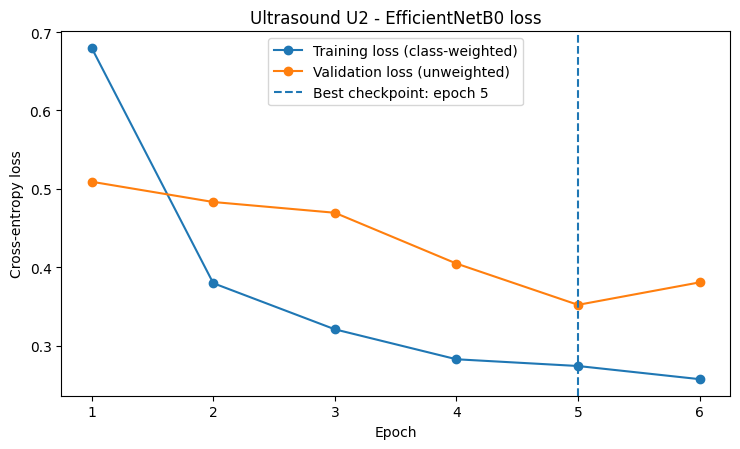

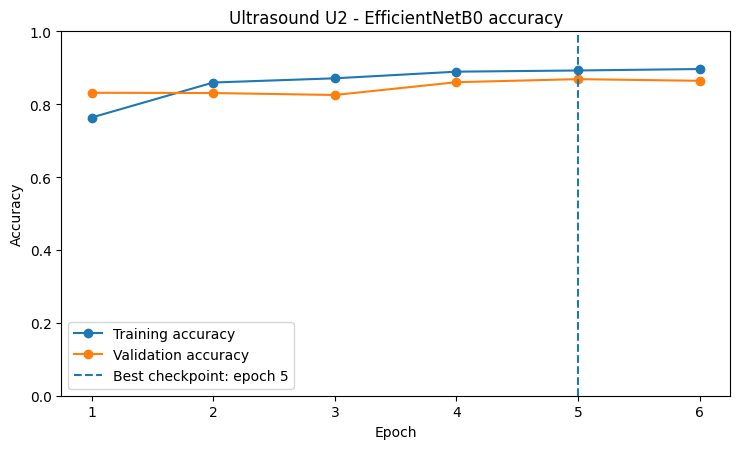

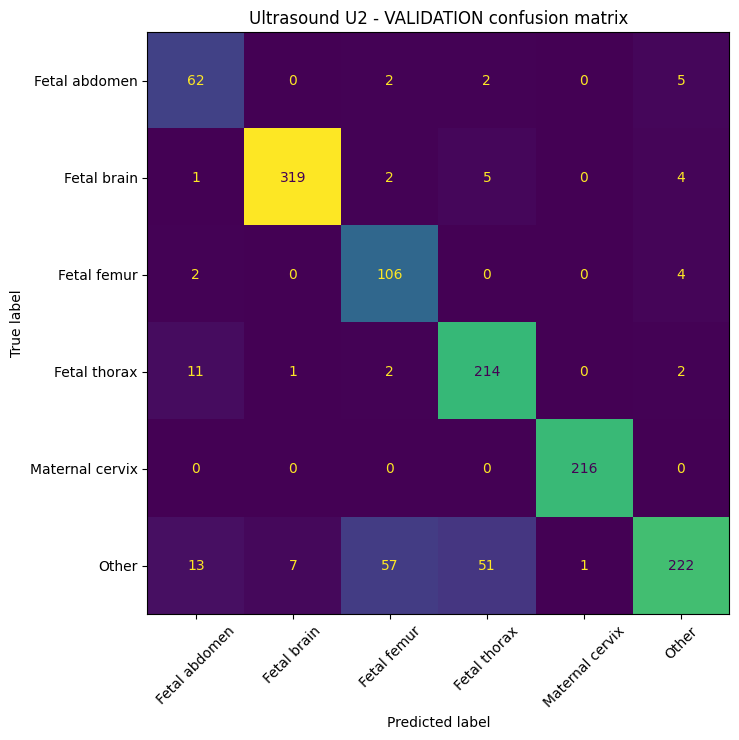

Saved artifacts:


,file,size_KiB
0,RUN_SUMMARY.md,2.1
1,U2_EfficientNetB0_frozen_seed42_evidence.zip,16022.1
2,artifact_checksums.json,2.2
3,best_model.keras,16735.5
4,class_mapping.json,0.1
5,comparison_u1_u2_validation.csv,0.3
6,configuration.json,2.9
7,data_checks.json,0.8
8,environment.json,0.5
9,evaluation_environment.json,0.5


Results folder: /content/drive/MyDrive/ICTIU_Final_Projects/ultrasound/results/U2_EfficientNetB0_frozen_seed42
U2 validation accuracy: 86.8802%
U2 validation macro-F1: 0.8507
Held-out test: not evaluated.


In [ ]:
# Save figures, measured run summary, and a checksum-verified evidence archive.
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

if sha256_file(RUN_DIR / 'best_model.keras') != validation_metrics['checkpoint_sha256']:
    raise ValueError('Checkpoint changed after evaluation.')
epoch_numbers = history_df['epoch'].to_numpy(dtype=int) + 1

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(epoch_numbers, history_df['loss'], marker='o', label='Training loss (class-weighted)')
ax.plot(epoch_numbers, history_df['val_loss'], marker='o', label='Validation loss (unweighted)')
ax.axvline(best_epoch, linestyle='--', label=f'Best checkpoint: epoch {best_epoch}')
ax.set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Ultrasound U2 - EfficientNetB0 loss')
ax.set_xticks(epoch_numbers)
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'training_loss.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(epoch_numbers, history_df['accuracy'], marker='o', label='Training accuracy')
ax.plot(epoch_numbers, history_df['val_accuracy'], marker='o', label='Validation accuracy')
ax.axvline(best_epoch, linestyle='--', label=f'Best checkpoint: epoch {best_epoch}')
ax.set(xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1),
       title='Ultrasound U2 - EfficientNetB0 accuracy')
ax.set_xticks(epoch_numbers)
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'training_accuracy.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 7.5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, values_format='d', colorbar=False)
ax.set_title('Ultrasound U2 - VALIDATION confusion matrix')
fig.tight_layout()
fig.savefig(RUN_DIR / 'validation_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# U1 values were reported in the reviewed handoff; they are not recomputed here.
reference_u1 = {'accuracy': 0.8810, 'macro_f1': 0.8572}
comparison = pd.DataFrame([
    {
        'experiment': 'U1_MobileNetV2_frozen_seed42',
        'backbone': 'MobileNetV2',
        'split': 'validation',
        'n_images': 1311,
        'accuracy': reference_u1['accuracy'],
        'macro_f1': reference_u1['macro_f1'],
        'evidence_source': '2026-10-19 handoff, previously measured U1 validation',
    },
    {
        'experiment': RUN_NAME,
        'backbone': 'EfficientNetB0',
        'split': 'validation',
        'n_images': len(val_df),
        'accuracy': validation_metrics['accuracy'],
        'macro_f1': validation_metrics['macro_f1'],
        'evidence_source': 'U2 best-checkpoint validation in this notebook',
    },
])
comparison.to_csv(RUN_DIR / 'comparison_u1_u2_validation.csv', index=False)

summary = f"""# {RUN_NAME} - measured experiment summary

## Scope
A frozen ImageNet EfficientNetB0 backbone with a six-class ultrasound classification head.
No fine-tuning, additional training augmentation, Grad-CAM, or held-out test evaluation.

## Dataset and protocol
FETAL_PLANES_DB: {EXPECTED_IMAGES['train']:,} training images,
{EXPECTED_IMAGES['validation']:,} validation images,
{EXPECTED_IMAGES['test']:,} held-out test images (unused).
The exact saved patient-disjoint split is reused, with {EXPECTED_PATIENTS['validation']}
validation patient IDs. No new split was generated.
Class order: {class_names}.
Images were resized with padding to {IMAGE_SIZE[0]} x {IMAGE_SIZE[1]} and
passed as float32 in [0, 255]. EfficientNetB0 includes its own preprocessing.
Batch size {BATCH_SIZE}, seed {SEED}, Adam learning rate {LEARNING_RATE},
head dropout {DROPOUT}, balanced training class weights and no extra augmentation.
Training cross-entropy uses class weights; validation loss is unweighted.

## Validation results (measured U2)
- Completed epochs: {len(history_df)} of {MAX_EPOCHS} maximum.
- Best checkpoint selected by minimum val_loss: epoch {best_epoch}.
- Validation loss: {validation_metrics['validation_loss']:.6f}.
- Validation accuracy: {validation_metrics['accuracy']:.6f}.
- Validation macro-F1: {validation_metrics['macro_f1']:.6f}.
- Validation weighted-F1: {validation_metrics['weighted_f1']:.6f}.

For reference, the handoff reports U1 validation accuracy
{reference_u1['accuracy']:.4f} and macro-F1 {reference_u1['macro_f1']:.4f}
on the same manifest. These U1 numbers were not recalculated by U2.
Confusion-matrix rows are true labels and columns are predicted labels.
Per-class precision/recall/F1 and per-image scores are exported separately.

## Interpretation and limitations
These are validation results, not held-out test performance or external clinical
validation. Class frequency and category-specific errors require consideration.
Softmax scores are uncalibrated model outputs, not medical confidence estimates.
The CSVLogger epoch column is zero-based; the report and figures use one-based epochs.

## Provenance
Checkpoint SHA-256: {validation_metrics['checkpoint_sha256']}
Manifest SHA-256: {SOURCE_SHA256['manifest']}
Archive MD5: {archive_md5}
Notebook revision: {CONFIG['notebook_revision']}

The executed notebook is saved separately from the evidence ZIP.
"""
(RUN_DIR / 'RUN_SUMMARY.md').write_text(summary, encoding='utf-8')

required_outputs = [
    'best_model.keras', 'configuration.json', 'class_mapping.json', 'environment.json',
    'data_checks.json', 'training_status.json', 'training_history.csv',
    'validation_metrics.json', 'validation_classification_report.txt',
    'validation_classification_report.csv', 'validation_predictions.csv',
    'validation_confusion_matrix.csv', 'validation_confusion_matrix.png',
    'training_loss.png', 'training_accuracy.png', 'train_val_image_index.csv',
    'evaluation_environment.json', 'model_summary.txt',
    'comparison_u1_u2_validation.csv', 'RUN_SUMMARY.md',
]
for name in required_outputs:
    path = RUN_DIR / name
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'Expected output missing or empty: {path}')
for role in ('manifest', 'mapping', 'audit'):
    expected = RUN_DIR / 'provenance' / SOURCE_FILES[role].name
    if not expected.is_file():
        raise FileNotFoundError(f'Missing source snapshot: {expected}')

zip_name = RUN_NAME + '_evidence.zip'
evidence_files = sorted(
    path for path in RUN_DIR.rglob('*')
    if path.is_file() and path.name not in {'artifact_checksums.json', zip_name}
    and not path.name.endswith('.tmp')
)
artifact_hashes = {str(path.relative_to(RUN_DIR)): sha256_file(path)
                   for path in evidence_files}
save_json(RUN_DIR / 'artifact_checksums.json', artifact_hashes)
LOCAL_EXPORT = Path('/content/ictiu_u2_exports')
LOCAL_EXPORT.mkdir(exist_ok=True)
local_zip_export = LOCAL_EXPORT / zip_name
with zipfile.ZipFile(local_zip_export, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in evidence_files + [RUN_DIR / 'artifact_checksums.json']:
        archive.write(path, arcname=str(Path(RUN_NAME) / path.relative_to(RUN_DIR)))
with zipfile.ZipFile(local_zip_export) as archive:
    if archive.testzip() is not None:
        raise IOError('Evidence archive ZIP verification failed.')
shutil.copy2(local_zip_export, RUN_DIR / zip_name)
if sha256_file(local_zip_export) != sha256_file(RUN_DIR / zip_name):
    raise IOError('Evidence archive copy to Drive changed unexpectedly.')

print('Saved artifacts:')
display(pd.DataFrame([
    {'file': str(path.relative_to(RUN_DIR)),
     'size_KiB': round(path.stat().st_size / 1024, 1)}
    for path in sorted(RUN_DIR.rglob('*')) if path.is_file()
]))
print('Results folder:', RUN_DIR)
print('U2 validation accuracy:', f'{validation_metrics["accuracy"]:.4%}')
print('U2 validation macro-F1:', f'{validation_metrics["macro_f1"]:.4f}')
print('Held-out test: not evaluated.')


## Reproducing a completed U2 run

After training and export, save this **executed** notebook separately in Google Drive (retain all code and outputs). Do not rerun the completed training section to reproduce validation results. In a fresh GPU Colab session, run Sections **1–5**, set `MODE = 'evaluate_saved'` in Section 3, then execute **6–7**, skip Section **8**, and execute **9–10**. Source fingerprints, configuration and the saved best checkpoint must still agree. This mode may regenerate validation figures and the evidence archive in the same completed run folder; it cannot overwrite model weights or restart training.

The official test partition remains reserved for a separate, predeclared final evaluation **after model selection and configuration are frozen on validation**. U1 and U2 should be compared by measured validation macro-F1, accuracy, per-class results, and confusion matrices; neither a larger architecture nor a higher accuracy alone proves clinical usefulness.

## Sources

- Dataset: [FETAL_PLANES_DB (Zenodo record 3904280)](https://zenodo.org/records/3904280).
- Model: [Keras EfficientNetB0 documentation](https://keras.io/api/applications/efficientnet/efficientnet_models/) (built-in EfficientNet normalization).
- Methodology: [Keras transfer learning and fine-tuning](https://keras.io/guides/transfer_learning/).
- Project records: `01_Ultrasound_MobileNetV2_Baseline.ipynb`, `PROJECT_HANDOFF_2026-10-19_UPDATED.md`, and the saved preparation manifest, class mapping and audit.
